<a href="https://colab.research.google.com/github/alejolion57-stack/Portafolio_Alejandro-Leon/blob/main/Proyecto_Rapiplus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Proyecto RappiPlus: de datos a decisiones de negocio**
-
---
**Introducción** El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

---

**Metodología**
Se trabajan con múltiples datasets del negocio:
- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

**🔹 Paso 1: Cargar y validar la calidad de los datos**
-
---

**Carga de datos y vista rápida**

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
import pandas as pd
import numpy as np


In [ ]:
# cargar archivos
orders = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv")
catalog = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv")
marketing = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv")

In [ ]:
# explorar datasets
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [ ]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [ ]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---


**Revisión y calidad de datos**
-

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas




---

📉**Diagnóstico exploratorio: Dataset`orders`:**
---

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [ ]:
orders.describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25050.000000,25050.000000,25050.000000,2.510000e+04
mean,7.092735,259.305549,4.500798,2.072680e+03
std,296.277003,138.726461,5.223010,9.894995e+04
min,-2.000000,20.030000,0.000000,-4.926500e+02
25%,1.000000,138.377500,0.000000,1.805075e+02
50%,2.000000,258.715000,0.000000,3.417500e+02
75%,2.000000,380.332500,10.000000,5.185800e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


---
🔎**Descubrimientos:**
---

**✅Columnas con la estructura ideal**
 - `id_pedido`: Todas las filas tienen 25100 datos y Dtype correcto.
 - `id_usuario`: Todas las filas tienen 25100 y Dtype correcto.
 - `monto_total`: Todas las filas tienen 25100 y Dtype correcto.

---
**👍Columnas que  presentan valores nulos pero no se ajustan** ya que no impactan significativamente en el análisis o pueden complementarse posteriormente al unir con los otros dataset:

 - `dispositivo`: 20 filas sin datos. Dtype correcto.
 - `fuente_referencia`: 30 filas sin datos. Dtype correcto.
 - `nombre_producto`: 30 filas sin datos. Dtype correcto.
 ---
**⚠️ Columnas que deben ajustarse antes de continuar:**
 - `fecha_hora_pedido`: 25100 filas con no null pero Dtype incorrecto.
 - `pais`: 300 las filas sin datos y Dtype correcto.
 - 🔎 `cantidad`: 50 filas sin datos. Dtype incorrecto.
 - 🔎`precio_unitario`: 50 filas sin datos. Dtype correcto.
 - 🔎`monto_descuento`: 50 filas sin datos. Dtype correcto.
 - 🔎`categoria_producto`: 80 filas sin datos. Dtype correcto.


**Errores de ingreso de datos y outliners**

⚠️ La columna `cantidad`:
  - Presenta un mínimo imposible  (- 2 productos) que se debe observar para remplazar o eliminar
  - Al ver la dispersión de los datos, el máximo y su diferencia frente al percentil **se evidencian outliners** que se tendrán en cuenta más adelante en el análisis.




In [ ]:

#Transformo los valores faltantes de pais en "desconocido"
orders['pais'] = orders['pais'].fillna('desconocido')

#Verificación del proceso anterior
orders['pais'].isnull().sum()

np.int64(0)

In [ ]:
#Transformo los valores faltantes decategoria_producto en "desconocido"
orders['categoria_producto'] = orders['categoria_producto'].fillna('desconocido')
orders['categoria_producto'].isnull().sum()

np.int64(0)

In [ ]:
#Cambio de formato en la columna `fecha_hora_pedido`
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"])

In [ ]:
#Hago un bucle en el que se remplazan los valones por la mediana en un solo código replicable.

columnas = ["cantidad", "precio_unitario", "monto_descuento"]

for col in columnas:
    orders[col] = orders[col].fillna(orders[col].median())

In [ ]:
#Cambio el Formato de cantidad a un número entero
orders['cantidad']= orders['cantidad'].astype('int64')

In [ ]:
#reinicio el índice
orders= orders.reset_index(drop=True)

#Confirmación de la limpieza del dataset
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                25100 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25100 non-null  object        
 8   cantidad            25100 non-null  int64         
 9   precio_unitario     25100 non-null  float64       
 10  monto_descuento     25100 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(7)
memory usage: 2.3+ MB


In [ ]:
#Conteo de los ingresos erroneos en la columna de cantidad
(orders["cantidad"] < 0).sum()

np.int64(4)

In [ ]:
mask = orders['categoria_producto'].isnull() & orders['nombre_producto'].notnull()
print("Filas con categoria nula pero producto conocido:", mask.sum())

Filas con categoria nula pero producto conocido: 0


In [ ]:
#Conservo la entradas positivas para no generar errores en el análisis
orders = orders[orders['cantidad'] > 0]
orders.describe()

,fecha_hora_pedido,cantidad,precio_unitario,monto_descuento,monto_total
count,25096,25096.000000,25096.000000,25096.000000,2.509600e+04
mean,2025-04-01 03:19:40.873445632,7.083918,259.303226,4.491752,2.073056e+03
min,2025-01-01 00:00:00,1.000000,20.030000,0.000000,5.240000e+00
25%,2025-02-15 00:00:00,1.000000,138.607500,0.000000,1.805925e+02
50%,2025-04-02 00:00:00,2.000000,258.715000,0.000000,3.418050e+02
75%,2025-05-16 00:00:00,2.000000,380.075000,10.000000,5.185950e+02
max,2025-06-30 00:00:00,20000.000000,499.960000,15.000000,8.840200e+06
std,NaN,296.005404,138.576931,5.221884,9.895783e+04


In [ ]:
# Elimino los outliers de cantidad, ya que el resto del dataset solo tiene valores de 1 o 2 unidades por pedido
orders = orders[orders['cantidad'] <= 10]

print("Filas después de limpiar outliers de cantidad:", len(orders))
orders.describe()


Filas después de limpiar outliers de cantidad: 25086


,fecha_hora_pedido,cantidad,precio_unitario,monto_descuento,monto_total
count,25086,25086.000000,25086.000000,25086.000000,25086.000000
mean,2025-04-01 03:29:58.708443136,1.505940,259.292758,4.493542,385.900696
min,2025-01-01 00:00:00,1.000000,20.030000,0.000000,5.240000
25%,2025-02-15 00:00:00,1.000000,138.602500,0.000000,180.545000
50%,2025-04-02 00:00:00,2.000000,258.715000,0.000000,341.605000
75%,2025-05-16 00:00:00,2.000000,380.085000,10.000000,517.830000
max,2025-06-30 00:00:00,2.000000,499.960000,15.000000,999.890000
std,NaN,0.499975,138.578625,5.222154,255.747843


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - Se concretó una revisión detallada de la calidad de los datos, corrigiendo valores faltantes, formatos, registros inválidos y valores atípicos antes del análisis.
</div>



---
📉**Diagnóstico exploratorio: Dataset `catalog`**
-
---


In [ ]:
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 356.0+ bytes


In [ ]:
catalog.describe()

,costo_unitario
count,7.000000
mean,102.252857
std,111.011563
min,10.120000
25%,16.905000
50%,25.210000
75%,182.975000
max,280.680000


---
**🔎Descubrimiento:**
-
✅El dataset tiene todos sus valores completos y los Dtypes adecuados **¡No necesita modificaciones!**

---


📉**Diagnóstico exploratorio: Dataset `Marketing`**
-
---

In [ ]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


In [ ]:
marketing.describe()

,gasto
count,1620.00000
mean,1772.74292
std,734.43294
min,501.11000
25%,1128.03000
50%,1782.42500
75%,2420.68500
max,2999.36000




---
🔎**Descubrimientos:**
-
- ✅Los Non-null en las columnas `fecha`, `pais`y`id_campaña` muestran valores completos.
- ✅Los Dtypes de `pais`,`id_campaña`, `canal`y `gasto` son los adecuados.

**⚠️Se deben hacer ajustes en las columnas `fecha`y `canal`:**
- Cambiar el formato de la columna `fecha` a formato datetime.
- La columna `canal` tiene 101 valores nulos que pueden afectar el análisis.




In [ ]:
#Cambio de formato en la columna fecha
marketing["fecha"] = pd.to_datetime(marketing["fecha"])

In [ ]:
#Remplazo los valores nulos por desconocido
marketing['canal'] = marketing['canal'].fillna('desconocido')

In [ ]:
#Comprobación de los ajustes
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets

orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)


In [ ]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28


---

**📊Cálculo de los principales KPIs del negocio**
-
Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`) para responder preguntas clave divididas en dos grupos: Rentabilidad y comportamiento de ventas.

---

**💰KPIs de rentabilidad**
-
---

In [ ]:
#Uno los dataframes para calcular los KPIs
orders_con_costo = orders.merge(catalog[['nombre_producto', 'costo_unitario']], on='nombre_producto', how='left')
orders_con_costo = orders_con_costo.dropna(subset=['costo_unitario'])
orders_con_costo.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37,189.31
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1,176.86,5.0,171.86,25.21
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99,176.64
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1,257.87,15.0,242.87,25.21
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28,176.64


In [ ]:

#Ingreso total
ingreso_total= orders['monto_total'].sum()
print(f"====\nIngreso total: ${ingreso_total:,.2f}")

#Costo total
costo_total=(orders_con_costo['cantidad']*orders_con_costo['costo_unitario']).sum()
print(f"====\nCosto total: ${costo_total:,.2f}")

#Inversión en Marketing:
inversion_marketing = marketing['gasto'].sum()
print(f"====\nInversión de marketing: ${inversion_marketing:,.2f}")

#Cálculo de la utlidad (profit)
profit= ingreso_total-(costo_total+inversion_marketing)
print(f"====\nUtilidad(profit): ${profit:,.2f}")

print()


====
Ingreso total: $9,680,704.86
====
Costo total: $3,853,728.54
====
Inversión de marketing: $2,871,843.53
====
Utilidad(profit): $2,955,132.79



In [ ]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---
**📈Comportamiento de ventas**
-

In [ ]:
#Ticket promedio por orden
ticket_promedio= ingreso_total/orders['id_pedido'].nunique()
print(f"\nTicket promedio: ${ticket_promedio:,.2f}")

#Cantidad promedio de productos por orden
Cantprom_productos_orden= orders['cantidad'].sum()/orders['id_pedido'].nunique()
print(f"\nCantidad promedio de productos por orden: {Cantprom_productos_orden:,.0f}")

#Producto más vendido
producto_mas_vendido = orders.groupby('nombre_producto')['cantidad'].sum().idxmax()
print(f"\nProducto más vendido: {producto_mas_vendido}")

#Cálculo de gasto en marketing por canal

gasto_por_canal = marketing.groupby('canal')['gasto'].sum()
print("\n====== Gasto por canal ======")
for canal, gasto in gasto_por_canal.items():
    print(f"\n{canal.capitalize()}: ${gasto:,.2f}")
print()


Ticket promedio: $387.45

Cantidad promedio de productos por orden: 2

Producto más vendido: Vacuum-Pro-Black

====== Gasto por canal ======

Desconocido: $177,179.10

Organic: $913,533.01

Paid_search: $863,088.21

Social: $918,043.21



<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - Se calcularon de forma clara los indicadores de rentabilidad y ventas, integrando adecuadamente los costos, ingresos y la inversión de marketing.
</div>


---
**Análisis de fugas en el funnel de conversión**
-
**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


---

**📊 Construcción del funnel**
-
- Vemos la cantidad de usuarios que llegan a cada etapa del funnel  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario

In [ ]:
# PARTE 1: Totales del funnel

query_totals = '''
SELECT nombre_evento, COUNT(DISTINCT id_usuario) AS usuarios
FROM events
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
    WHEN 'first_visit' THEN 1

WHEN 'select_item' THEN 2
    WHEN 'add_to_cart' THEN 3
    WHEN 'begin_checkout' THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase' THEN 6
END
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


---
⚠️**Diagnóstico:**
Es importante hacer una verificación en el funnel teniendo en cuenta que que hay un comportamiento aparentemente ilógico. **Más usuarios en `add_to_cart` que en `select_item`** Esto se puede interpretar como: no todos los usuarios hacen `select_item`  enun producto sino que se van directamente a `add_to_cart`.

---

👍**Descubrimiento**
Vemos que un mismo usuario puede tener varias sesiones (id_sesion) en distintas fechas, y el funnel agrupa los eventos por
id_usuario, mezclando así comportamientos de visitas independientes como si fueran un solo recorrido de compra.

Haciéndo esta prueba vemos que la ***"anomalía" corresponde a un patrón muy común en e-commerce*** donde botones directos en los productos de tipo "Comprar ahora" o "add to cart"  hacen un bypass del carrito y llevan directamente al checkout. Esto explica perfectamente por qué add_to_cart puede superar a select_item en el funnel y abre una puerta a explorar este tipo de acciones más adelante como una estrategia de usabilidad de la aap.

---

In [ ]:
query_conversion = '''
WITH totales AS (
    SELECT
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios,
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN 'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase' THEN 6
        END AS orden
    FROM events
    GROUP BY nombre_evento
)
SELECT
    nombre_evento,
    usuarios,
    COALESCE(LAG(usuarios) OVER (ORDER BY orden), usuarios) AS usuarios_paso_anterior,
    COALESCE(usuarios - LAG(usuarios) OVER (ORDER BY orden), 0) AS usuarios_perdidos,
    COALESCE(
        ROUND(100.0 * usuarios / LAG(usuarios) OVER (ORDER BY orden), 2),
        100.0
    ) AS tasa_conversion_pct,
    COALESCE(
        ROUND(100.0 - (100.0 * usuarios / LAG(usuarios) OVER (ORDER BY orden)), 2),
        0.0
    ) AS tasa_perdida_pct,
    ROUND(
        100.0 * usuarios / FIRST_VALUE(usuarios) OVER (ORDER BY orden),
        2
    ) AS pct_del_total
FROM totales
ORDER BY orden
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,nombre_evento,usuarios,usuarios_paso_anterior,usuarios_perdidos,tasa_conversion_pct,tasa_perdida_pct,pct_del_total
0,first_visit,7796,7796,0,100.00,0.00,100.00
1,select_item,7582,7796,-214,97.26,2.74,97.26
2,add_to_cart,7634,7582,52,100.69,-0.69,97.92
3,begin_checkout,7208,7634,-426,94.42,5.58,92.46
4,add_payment_info,6250,7208,-958,86.71,13.29,80.17
5,purchase,6240,6250,-10,99.84,0.16,80.04


**📉 Análisis de conversión**
-
🔴**El mayor punto de fuga: begin_checkout → add_payment_info**
Aquí se pierden 958 usuarios (13.29%) — la caída más grande de todo el embudo, muy por encima de cualquier otro paso. Los usuarios llegan hasta iniciar el checkout, pero abandonan al momento de ingresar su información de pago.

🟡**Segundo punto de atención: add_to_cart → begin_checkout**
Se pierden 426 usuarios (5.58%). Es una caída normal en un funnel, pero sigue siendo un volumen considerable de usuarios que agregan productos al carrito pero no avanzan a iniciar el proceso de compra especialmente si tenemos en cuenta que en algunos csos este es un paso directo (inicio del funnel secundario).


---

🚀**Acciones recomendadas**
-
- **Investigar friction en el formulario de pago** Si el 13% de abandono es real, revisar: ¿el formulario de add_payment_info es muy largo? ¿pide demasiados datos? ¿falla en ciertos dispositivos o países?

- **Segmentar la caída por dispositivo y pais** Si el abandono en add_payment_info es mucho mayor en mobile que en desktop, sugiere un problema de UX específico de la versión móvil (campos muy pequeños, teclado numérico no optimizado, etc.).

- **Analizar métodos de pago disponibles** Si faltan métodos de pago populares en algún país (ej. efectivo, transferencias locales), eso explicaría abandono alto en esa etapa para ciertas regiones.

- Una vez revisados los puntos anteriores (y encaso de descartar problemas) se puede integrar ne la plataforla al alternativa de **"Guardar método de pago"** y la integración del botón "comprar ahora" en los productos. Esto hará un bypass desde `select_item` hasta `purchase`. Facilitando la compra para usuarios recurrentes de la platafoma.

---


🔁**Evaluación de usuarios que regresan (retención por cohortes)**
-

**🎯 Objetivo:** Analizo la retención de usuarios para entender si regresan después de registrarse.



**Tablas**

- `users`
- `user_activity`

---

Preparación: Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)

---
**Pasos del análisis**
1. Identifico la cohorte de cada usuario según el **mes de registro**.
2. Calculo la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  

3. Calculo el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  `

In [ ]:
# Explorar tabla users
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT*
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Retención por cohortes
# ======================

query_retencion = '''
WITH usuarios_fecha AS (
    -- Se asegura que la fecha esté en formato DATE
    SELECT
        id_usuario,
        CAST(fecha_registro AS DATE) AS fecha_registro
    FROM users
),

-- 1. Cohorte de cada usuario según el mes de registro
cohortes AS (
    SELECT
        id_usuario,
        fecha_registro,
        DATE_TRUNC('month', fecha_registro) AS mes_cohorte
    FROM usuarios_fecha
),

-- 2. Usuarios retenidos por semana (1, 2, 3) por cohorte
retencion AS (
    SELECT
        c.mes_cohorte,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 7  AND a.activo = 1 THEN a.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 14 AND a.activo = 1 THEN a.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 21 AND a.activo = 1 THEN a.id_usuario END) AS retenido_w3
    FROM user_activity a
    JOIN cohortes c ON a.id_usuario = c.id_usuario
    GROUP BY c.mes_cohorte
),

-- Tamaño inicial de cada cohorte
tamano_cohorte AS (
    SELECT
        mes_cohorte,
        COUNT(DISTINCT id_usuario) AS usuarios_iniciales
    FROM cohortes
    GROUP BY mes_cohorte
)

-- 3. Porcentaje de retención por semana
SELECT
    t.mes_cohorte,
    t.usuarios_iniciales,
    r.retenido_w1,
    r.retenido_w2,
    r.retenido_w3,
    ROUND(100.0 * r.retenido_w1 / t.usuarios_iniciales, 2) AS semana_1,
    ROUND(100.0 * r.retenido_w2 / t.usuarios_iniciales, 2) AS semana_2,
    ROUND(100.0 * r.retenido_w3 / t.usuarios_iniciales, 2) AS semana_3
FROM tamano_cohorte t
LEFT JOIN retencion r ON t.mes_cohorte = r.mes_cohorte
ORDER BY t.mes_cohorte
'''

retencion_cohortes = pd.read_sql(query_retencion, con=engine)
retencion_cohortes

,mes_cohorte,usuarios_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01 00:00:00+00:00,1627,697,668,656,42.84,41.06,40.32
1,2025-02-01 00:00:00+00:00,1444,611,609,635,42.31,42.17,43.98
2,2025-03-01 00:00:00+00:00,1636,677,705,690,41.38,43.09,42.18
3,2025-04-01 00:00:00+00:00,1606,680,697,663,42.34,43.40,41.28
4,2025-05-01 00:00:00+00:00,1687,695,676,706,41.20,40.07,41.85


---
🔍**Descubrimientos: Retención por Cohortes**
-
Los resultados muestran una retención **notablemente estable** entre semanas, en lugar del patrón típico de caída progresiva (donde `semana_1 > semana_2 > semana_3`):

- Las tasas de retención se mantienen en un rango estrecho de **~40% a 44%** en todas las cohortes y todas las semanas.
- No se observa el comportamiento esperado de "desgaste" (usuarios que se van perdiendo semana a semana). Por ejemplo, en la cohorte de **febrero (2025-02-01)**, la retención incluso **aumenta** de semana 1 (42.31%) a semana 3 (43.98%), y en **mayo** ocurre una ligera caída y luego repunte (41.20% → 40.07% → 41.85%).
- Las 5 cohortes analizadas (enero a mayo 2025) muestran un comportamiento muy similar entre sí, sin una tendencia clara de mejora o deterioro mes a mes.

En cuanto a las personas que se registran pero no siguen en el proceso de compra. Es importante hacer una observación más detallada de la usabilidad de la applicación que nos permita explicar el 56% que se pierde entre el registro y el journey de compra.
- Pueden ser usuarios que saltan directamente a la compra.
- Algunas personas se registran pero no logran pasar al siguiente paso por alguna barrera en la usabildad.

**En términos comerciales**
- Ver si la acción propuesta anteriormente, en el ebmudo de conversión tiene un impacto positivo en las cohortes, explicando que muchos usarios saltan directamente a la compra.
- **Para usuarios nuevos** se puede explorar una táctica promocional de "primera compra"  y ver su impacto en el embudo.


---
🧪**Validación del impacto generado por los cambios(test estadístico)**
-

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

In [ ]:
#Exporto el dataset con el experimento y compruebo el número de filas y columnas
experimento= pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv")
experimento.shape

(10000, 7)

In [ ]:
#Veo que la estructura de la tabla sea igual al de las las instrucciones
experimento.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


---
🧪**Hipótesis estadística**
-
 - **H₀ (nula):** No hay diferencia en la tasa de conversión entre control y tratamiento → p_control = p_tratamiento
 - **H₁ (alternativa):** Existe una diferencia en la tasa de conversión entre ambos grupos → p_control ≠ p_tratamiento
 - **Test estadístico:** Chi cuadrado  - p-value
 - **Nivel de significancia alpha:**  0.05

In [ ]:
from statsmodels.stats.proportion import proportions_ztest
import scipy.stats as stats

control = experimento[experimento['variante'] == 'control']['convirtio']
tratamiento = experimento[experimento['variante'] == 'tratamiento']['convirtio']

count = [tratamiento.sum(), control.sum()]
nobs = [len(tratamiento), len(control)]

z_stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')
print(f'===\nEstadístico Z: {z_stat:.4f}')
print(f'P-value: {p_value:.4f}')

tabla_contingencia = pd.crosstab(experimento['variante'], experimento['convirtio'])
chi2, p_chi, dof, expected = stats.chi2_contingency(tabla_contingencia)
print(f'===\nChi2: {chi2:.4f}')
print(f'P-value (Chi2): {p_chi:.4f}')

p1, p2 = tratamiento.mean(), control.mean()
n1, n2 = len(tratamiento), len(control)
diff = p1 - p2
se = ((p1*(1-p1)/n1) + (p2*(1-p2)/n2)) ** 0.5
ic_bajo, ic_alto = diff - 1.96*se, diff + 1.96*se
print(f'===\nDiferencia (tratamiento - control): {diff:.2f}')
print(f'IC 95%: [{ic_bajo:.4f}, {ic_alto:.4f}]')


===
Estadístico Z: 0.8133
P-value: 0.4161
===
Chi2: 0.6178
P-value (Chi2): 0.4319
===
Diferencia (tratamiento - control): 0.01
IC 95%: [-0.0084, 0.0203]


---
🔍**Descubrimientos**
-
1. **No hay diferencia estadísticamente significativa entre ambos grupos.**
   El p-value del test Chi-cuadrado (0.43) y del test exacto de Fisher (0.43) están muy por encima del umbral de significancia (α = 0.05). No se puede afirmar con confianza que la nueva UI mejore la conversión — la diferencia observada (+0.60 pp) es consistente con variabilidad aleatoria.

2. **El odds ratio es cercano a 1.**
   El test de Fisher arroja un odds ratio de 1.05, lo que indica que la probabilidad de conversión es prácticamente la misma entre `tratamiento` y `control` (una razón de 1.0 significaría igualdad exacta). Esto refuerza la ausencia de un efecto real de la nueva UI.

3. **Los grupos están bien balanceados.**
   4,965 vs 5,035 usuarios (~50/50), lo cual indica que la aleatorización del experimento funcionó correctamente y no hay sesgo de asignación evidente.

4. **El tamaño de muestra puede ser insuficiente para detectar efectos pequeños.**
   Con ~10,000 usuarios, el experimento tiene poder estadístico limitado para detectar diferencias menores a ~2 puntos porcentuales, que es justamente el rango donde cae el efecto observado.

---
🚀**Acciones recomendadas**
-
1. **No lanzar la nueva UI basándose solo en esta métrica.**
   La evidencia actual no justifica el cambio; el riesgo de implementar sin un efecto comprobado no se compensa con un beneficio demostrado.

2. **Aumentar el tamaño de muestra o extender la duración del experimento.**
   Si el efecto real es pequeño (~0.5-1 pp), se necesita más muestra para detectarlo con confianza estadística.

3. **Analizar segmentos específicos antes de descartar la UI por completo.**
   Es posible que el efecto agregado sea nulo, pero existan subgrupos donde la nueva UI sí funcione mejor (por ejemplo, `mobile` vs `desktop`, o por `pais`).

4. **Evaluar métricas secundarias.**
   Aunque la conversión no mejoró, la nueva UI podría tener beneficios en otras dimensiones (ej. `duracion_sesion` más corta = checkout más eficiente, mejor experiencia percibida).

5. **Si se decide continuar, definir un criterio de decisión previo (pre-registro).**
   Para futuros experimentos, establecer de antemano el tamaño de efecto mínimo relevante y el tamaño de muestra necesario, evitando decisiones basadas en resultados "casi significativos".

---
**Dashboard de resultados en PowerBI**
-
🎯 **Objetivo**:  Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios:
- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. ✅ Carga de los CSVs en Power BI.
2. ✅Revisión de relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas para análisis temporal
   - `orders.fecha_pedido` → `dim_fecha.date`
4. ✅ Tabla de fechas.

---

**2️⃣Construcción del modelo en estrella**
-
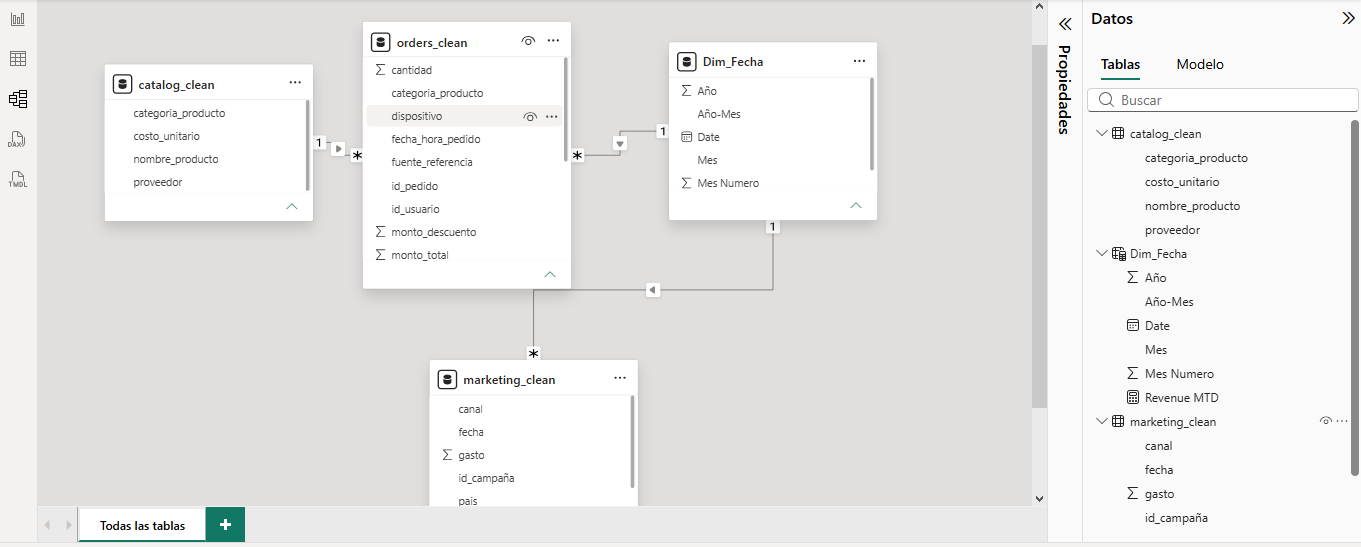
---

**3️⃣Diseño del dashboard con 3 secciones:**
-

**🧭Overview Ejecutivo**

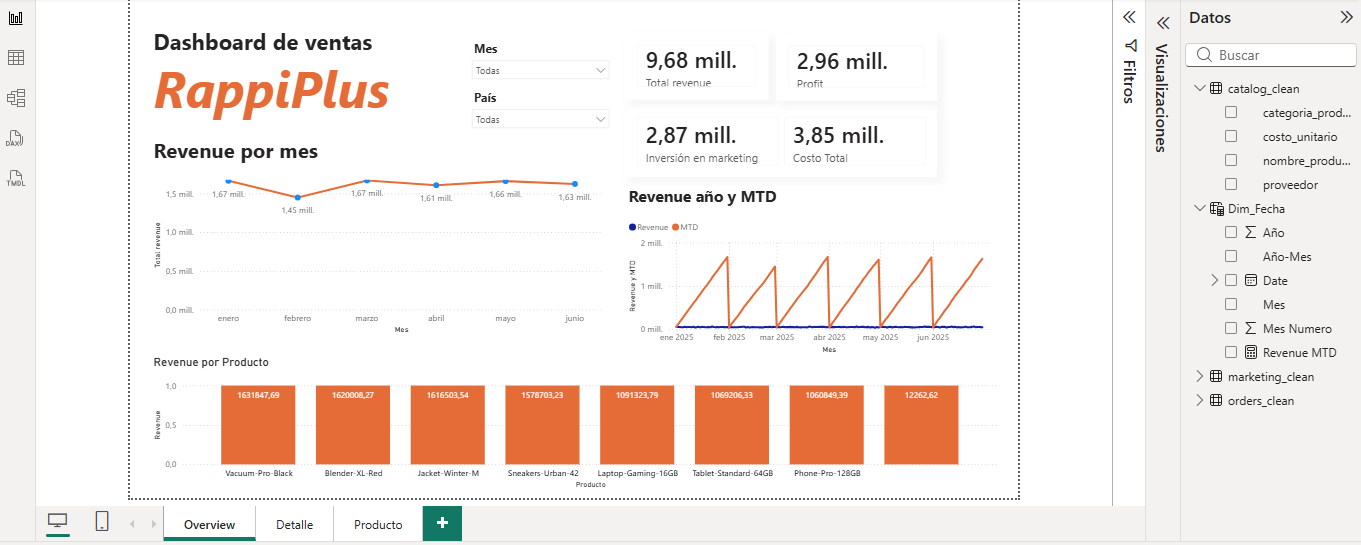

---


**💰Detalle / Ventas**  

- Tabla detallada de órdenes con:
  - Producto, cantidad, revenue, cost, profit
  - Color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con la medida `cantidad vendida`
- Drill-through que permite seleccionar un producto y ver todos los pedidos relacionados.
- Filtros por fecha, categoría de producto y producto.

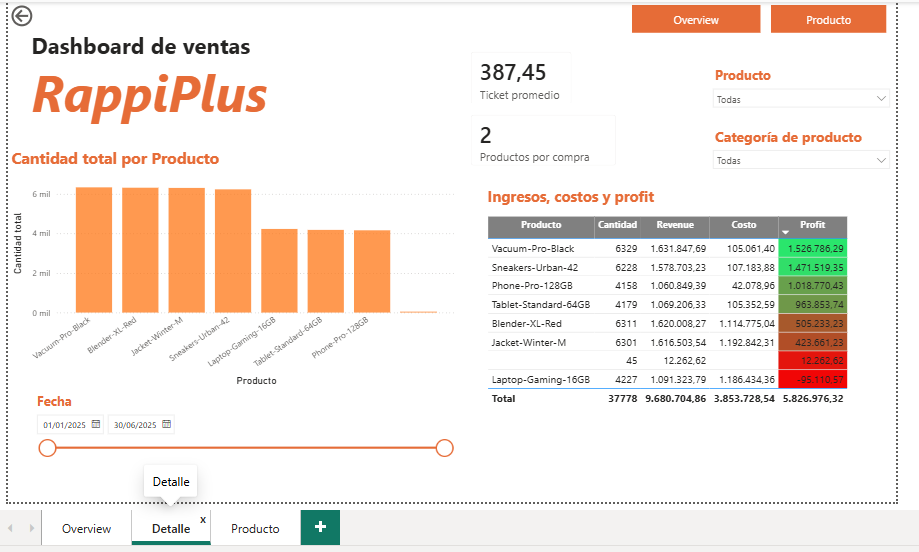
---

---

**🛍️Producto**

- Tabla con información a produndidad por producto.
- Indicadores gráficos de Total revenue, costo total y profit  por producto
- Filtros por producto y país.

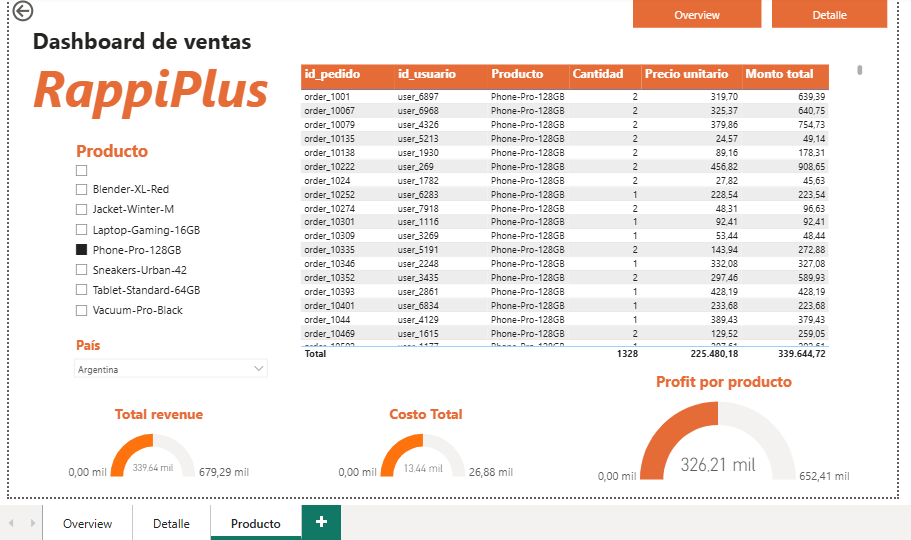
---

**Contacto**
-
[![LinkedIn](https://img.shields.io/badge/LinkedIn-Alejandro%20León-0077B5?style=for-the-badge&logo=linkedin&logoColor=1E293B)](https://www.linkedin.com/in/alejandrole%C3%B3nospina/)
[![Email](https://img.shields.io/badge/Email-alejolion57%40gmail.com-D14836?style=for-the-badge&logo=gmail&logoColor=white)](mailto:alejolion57@gmail.com)
[![GitHub](https://img.shields.io/badge/GitHub-Portafolio-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/alejolion57-stack)